Prepare and Clean the dataset

In [6]:
import os
import pandas as pd

# ================= Configuration =================
# Replace these paths with your actual input and output folder paths
INPUT_FOLDER = "excels"
OUTPUT_FOLDER = "csvs"
# =================================================

def convert_excel_to_csv(input_folder, output_folder):
    """
    Convert all .xlsx and .xls files in the input folder to .csv files.
    If an Excel file contains multiple sheets, each sheet will be saved as a separate CSV file.
    """
    # Create output folder if it doesn't exist
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)

    # Supported Excel extensions
    excel_extensions = ('.xlsx', '.xls')

    # Iterate through all files in the input folder
    for filename in os.listdir(input_folder):
        if filename.lower().endswith(excel_extensions):
            file_path = os.path.join(input_folder, filename)
            base_name = os.path.splitext(filename)[0]

            print(f"Processing: {filename}")

            try:
                # Determine the engine based on file extension
                if filename.lower().endswith('.xlsx'):
                    engine = 'openpyxl'
                else:
                    try:
                        pd.ExcelFile(file_path, engine='xlrd')
                        engine = 'xlrd'
                    except Exception:
                        engine = 'openpyxl'
                excel_file = pd.ExcelFile(file_path, engine=engine)

                # Load all sheets from the Excel file
                excel_file = pd.ExcelFile(file_path, engine=engine)

                for sheet_name in excel_file.sheet_names:
                    # Read the specific sheet
                    df = pd.read_excel(excel_file, sheet_name=sheet_name)

                    # Generate output CSV filename
                    # If there are multiple sheets, append the sheet name to the filename
                    if len(excel_file.sheet_names) > 1:
                        csv_filename = f"{base_name}_{sheet_name}.csv"
                    else:
                        csv_filename = f"{base_name}.csv"

                    csv_path = os.path.join(output_folder, csv_filename)

                    # Save to CSV with utf-8-sig encoding (ensures Chinese characters display correctly in Excel)
                    df.to_csv(csv_path, index=False, encoding='utf-8-sig')
                    print(f"  -> Saved: {csv_filename}")

            except Exception as e:
                print(f"  -> Error processing {filename}: {e}")

    print("\nConversion completed!")


if __name__ == "__main__":
    convert_excel_to_csv(INPUT_FOLDER, OUTPUT_FOLDER)

Processing: 4. School_num_ias.xls
  -> Error processing 4. School_num_ias.xls: File is not a zip file
Processing: 5. Public expenditure_nontertiary_ias.xls
  -> Error processing 5. Public expenditure_nontertiary_ias.xls: File is not a zip file
Processing: .~6. Students_enrolled_3 education_stages_dsec.xlsx
  -> Error processing .~6. Students_enrolled_3 education_stages_dsec.xlsx: File is not a zip file
Processing: 1. Birth rate_ias.xls
  -> Error processing 1. Birth rate_ias.xls: File is not a zip file
Processing: .~5. Public expenditure_nontertiary_ias.xlsx
  -> Error processing .~5. Public expenditure_nontertiary_ias.xlsx: File is not a zip file
Processing: .~7. Teacher nums_Total+3stages.xlsx
  -> Error processing .~7. Teacher nums_Total+3stages.xlsx: File is not a zip file
Processing: .~8. Pupil-teacher ratio_dsec.xlsx
  -> Error processing .~8. Pupil-teacher ratio_dsec.xlsx: File is not a zip file
Processing: .~4. School_num_ias.xlsx
  -> Error processing .~4. School_num_ias.xlsx:

Figure 1

In [56]:
import matplotlib.pyplot as plt

# ==========================================
# 1. Setup Fonts (English Only)
# ==========================================
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['axes.unicode_minus'] = False

# ==========================================
# 2. Load and Process Data
# ==========================================
# Load Education Enrollment Data
df_edu = pd.read_csv('csvs/6. Students_enrolled_3 education_stages_dsec.csv', encoding='utf-8-sig')
df_edu.columns = [col.replace('\n', ' ').strip() for col in df_edu.columns]
df_edu = df_edu.rename(columns={
    'Unnamed: 0': 'Year_Range',
    'Students enrolled Pre-primary education': 'Pre_primary',
    'Students enrolled Primary education': 'Primary',
    'Students enrolled Secondary (Inclued vocational-technical) education': 'Secondary'
})

# Extract year and filter up to 2024
df_edu['Year'] = df_edu['Year_Range'].apply(lambda x: int(str(x).split('/')[0]))
df_edu = df_edu[df_edu['Year'] <= 2024].reset_index(drop=True)

# Calculate Total and Percentages
df_edu['Total'] = df_edu['Pre_primary'] + df_edu['Primary'] + df_edu['Secondary']
df_edu['Pre_primary_pct'] = (df_edu['Pre_primary'] / df_edu['Total']) * 100
df_edu['Primary_pct'] = (df_edu['Primary'] / df_edu['Total']) * 100
df_edu['Secondary_pct'] = (df_edu['Secondary'] / df_edu['Total']) * 100

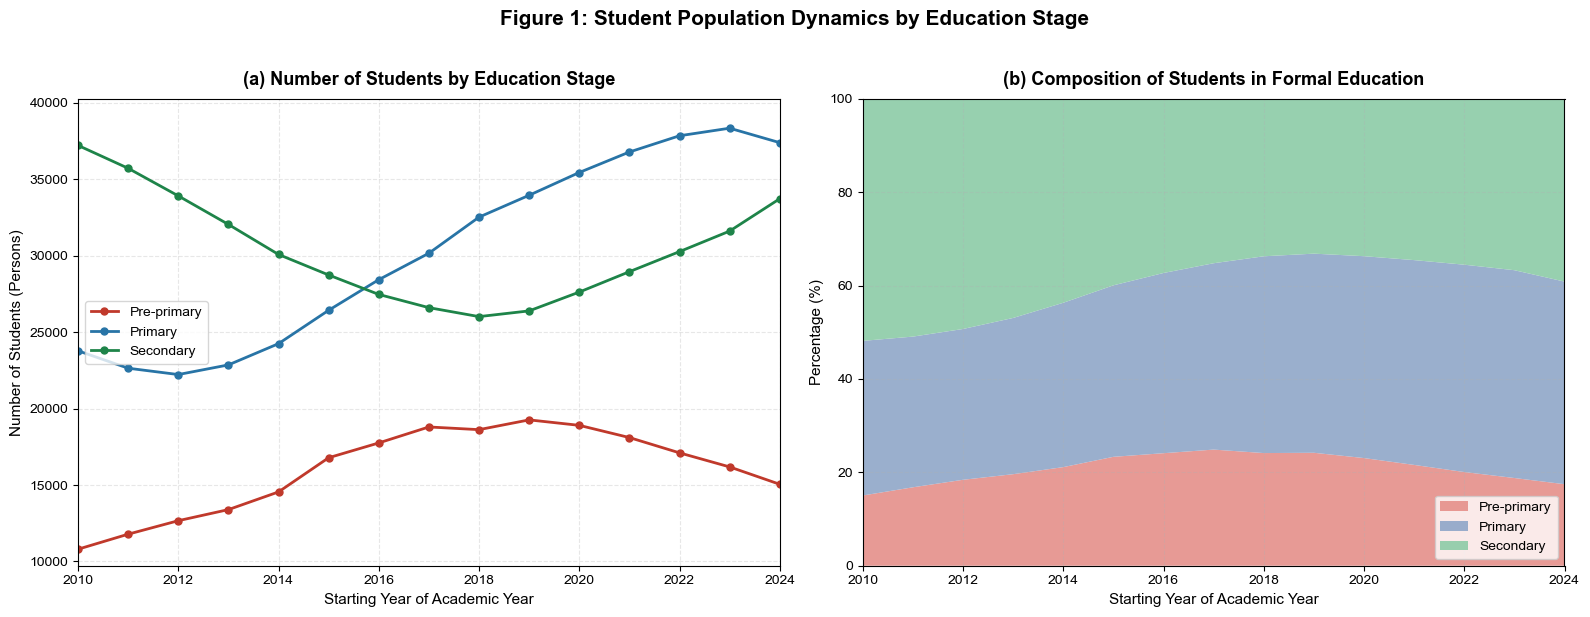

In [57]:
# ==========================================
# 3. Plotting (1 row, 2 columns)
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ------------------------------------------
# Left Plot (ax1): Line Chart (Absolute Numbers)
# ------------------------------------------
colors_line = {'Pre_primary': '#C0392B', 'Primary': '#2874A6', 'Secondary': '#1E8449'}
labels_line = {'Pre_primary': 'Pre-primary', 'Primary': 'Primary', 'Secondary': 'Secondary'}

for col in colors_line.keys():
    ax1.plot(df_edu['Year'], df_edu[col], marker='o', markersize=5, 
             linestyle='-', linewidth=2, color=colors_line[col], label=labels_line[col])

# Formatting ax1
ax1.set_title('(a) Number of Students by Education Stage', fontsize=13, pad=10, fontweight='bold')
ax1.set_xlabel('Starting Year of Academic Year', fontsize=11)
ax1.set_ylabel('Number of Students (Persons)', fontsize=11)
ax1.set_xlim(df_edu['Year'].min(), df_edu['Year'].max())
ax1.set_xticks(np.arange(2010, 2025, 2))

# Set Y-axis limits based on real data (adding a little padding)
min_students = df_edu[list(colors_line.keys())].min().min()
max_students = df_edu[list(colors_line.keys())].max().max()
ax1.set_ylim(min_students * 0.9, max_students * 1.05)

ax1.grid(True, linestyle='--', alpha=0.3)
ax1.legend(loc='center left', frameon=True)

# ------------------------------------------
# Right Plot (ax2): Stacked Area Chart (Percentages)
# ------------------------------------------
colors_area = ['#E58F8A', '#8FA6C8', '#8CCBA7']
labels_area = ['Pre-primary', 'Primary', 'Secondary']

ax2.stackplot(df_edu['Year'], 
              df_edu['Pre_primary_pct'], df_edu['Primary_pct'], df_edu['Secondary_pct'],
              labels=labels_area, colors=colors_area, alpha=0.9)

# Formatting ax2
ax2.set_title('(b) Composition of Students in Formal Education', fontsize=13, pad=10, fontweight='bold')
ax2.set_xlabel('Starting Year of Academic Year', fontsize=11)
ax2.set_ylabel('Percentage (%)', fontsize=11)
ax2.set_xlim(df_edu['Year'].min(), df_edu['Year'].max())
ax2.set_ylim(0, 100)
ax2.set_xticks(np.arange(2010, 2025, 2))
ax2.grid(True, linestyle='--', alpha=0.3)
ax2.legend(loc='lower right', frameon=True)

# ==========================================
# 4. Final Layout and Save
# ==========================================
# Main overarching title
fig.suptitle('Figure 1: Student Population Dynamics by Education Stage', 
             fontsize=15, fontweight='bold', y=1.02)

plt.tight_layout()
# Save the combined chart
plt.savefig('Figures/Figure1_Combined_Charts.png', dpi=300, bbox_inches='tight')
plt.show()

Figure 2

In [40]:
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
# ==========================================
# 1. Setup Fonts
# ==========================================
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['axes.unicode_minus'] = False

# ==========================================
# 2. Load Datasets
# ==========================================
df_births = pd.read_csv('csvs/2. Live births_dsec.csv', encoding='utf-8-sig')
df_births.columns = ['Year', 'Live_Births']

df_edu = pd.read_csv('csvs/6. Students_enrolled_3 education_stages_dsec.csv', encoding='utf-8-sig')
df_edu.columns = [col.replace('\n', ' ').strip() for col in df_edu.columns]
df_edu = df_edu.rename(columns={
    'Unnamed: 0': 'Year_Range',
    'Students enrolled Pre-primary education': 'Pre_primary',
    'Students enrolled Primary education': 'Primary',
    'Students enrolled Secondary (Inclued vocational-technical) education': 'Secondary'
})
# Convert '2010/2011' to int 2010
df_edu['Year'] = df_edu['Year_Range'].apply(lambda x: int(str(x).split('/')[0]))
df_edu = df_edu.drop(columns=['Year_Range'])

# ==========================================
# 3. Align Years by Absolute Shifting (The Fix)
# ==========================================
# Create shifted dataframes by adding lag years to the 'Year' column
df_births_3 = df_births.copy()
df_births_3['Year'] += 3  # 2010 births will now be labeled as 2013

df_births_6 = df_births.copy()
df_births_6['Year'] += 6

df_births_12 = df_births.copy()
df_births_12['Year'] += 12

# ==========================================
# 4. Merge Datasets Correctly
# ==========================================
# Merge Education data with the 3-year shifted births for Pre-primary
df_pre = pd.merge(df_edu[['Year', 'Pre_primary']], df_births_3, on='Year', how='inner')

# Merge Education data with the 6-year shifted births for Primary
df_pri = pd.merge(df_edu[['Year', 'Primary']], df_births_6, on='Year', how='inner')

# Merge Education data with the 12-year shifted births for Secondary
df_sec = pd.merge(df_edu[['Year', 'Secondary']], df_births_12, on='Year', how='inner')

df_pre.head()

,Year,Pre_primary,Live_Births
0,2013,13395,5114
1,2014,14552,5852
2,2015,16789,7315
3,2016,17757,6571
4,2017,18802,7360


Chart successfully saved to current directory as: Figures/Figure2_Macao_Births_vs_Education_TimeLag_Fixed.png


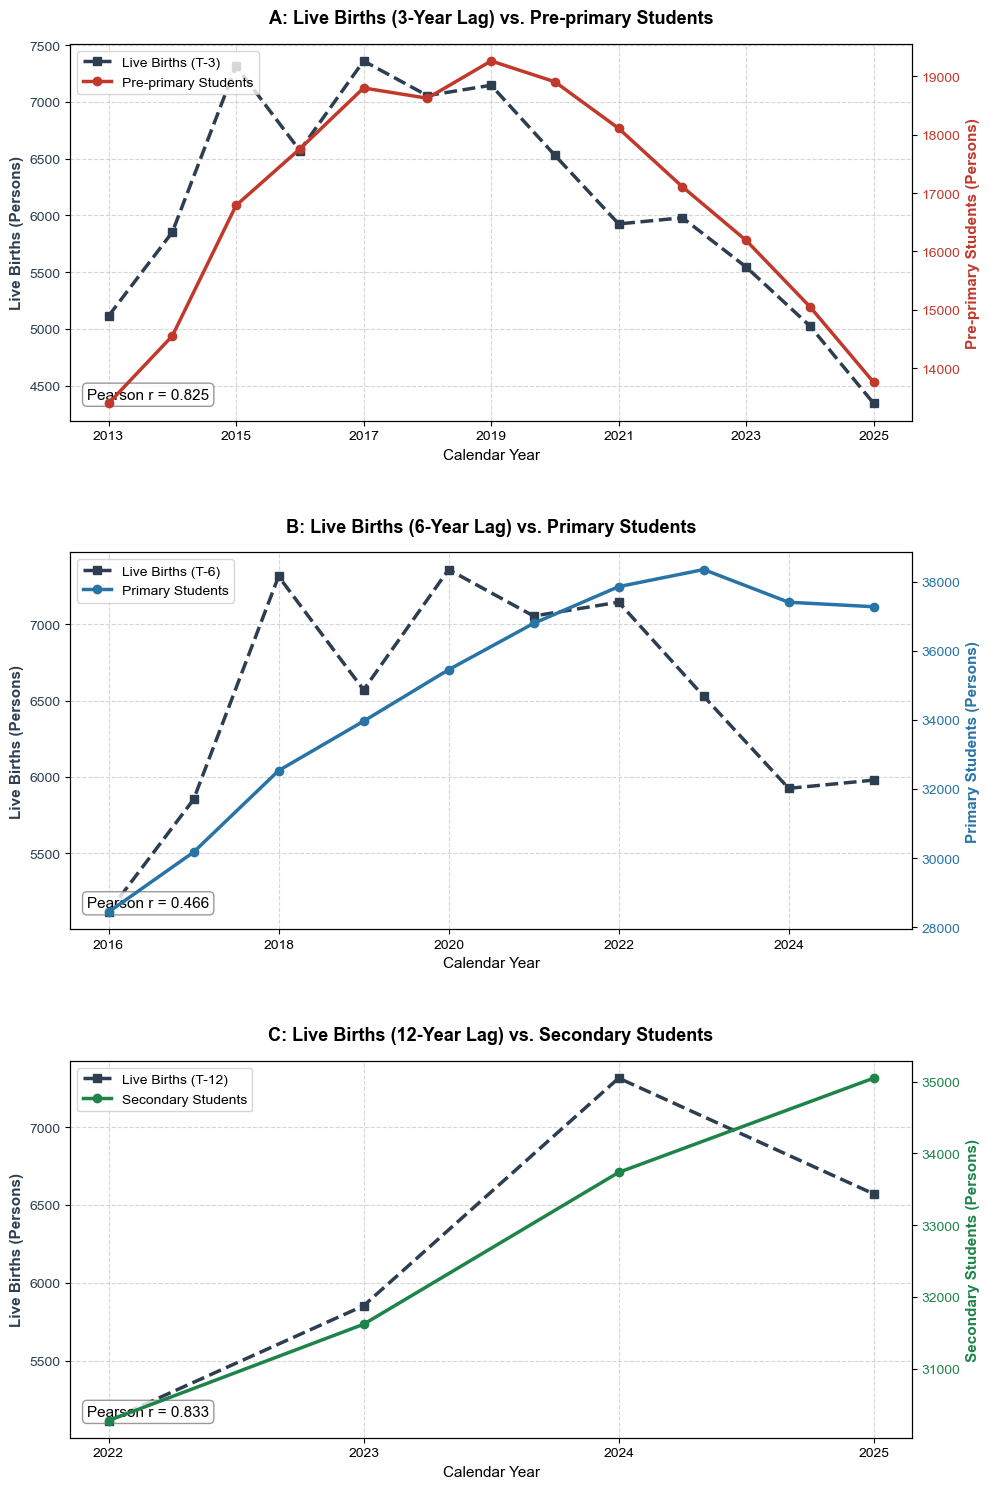

In [37]:
# ==========================================
# 5. Plotting Setup (3 Subplots)
# ==========================================
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 15))

# --- Helper function for formatting ---
def format_axis(ax, title, y1_label, y2_label, color1, color2, df):
    ax_twin = ax.twinx()
    ax.set_title(title, fontsize=13, pad=15, fontweight='bold')
    ax.set_xlabel('Calendar Year', fontsize=11)
    ax.set_ylabel(y1_label, fontsize=11, color=color1, fontweight='bold')
    ax_twin.set_ylabel(y2_label, fontsize=11, color=color2, fontweight='bold')
    ax.tick_params(axis='y', labelcolor=color1)
    ax_twin.tick_params(axis='y', labelcolor=color2)
    ax.grid(True, linestyle='--', alpha=0.5)
    
    # Auto-adjust x-ticks based on the actual data range to avoid overlapping
    min_year, max_year = int(df['Year'].min()), int(df['Year'].max())
    # Use step=2 if range is large, step=1 if small
    step = 2 if (max_year - min_year) > 5 else 1 
    ax.set_xticks(range(min_year, max_year + 1, step))
    
    return ax_twin

# ==========================================
# Chart 1: Pre-primary (3-year lag)
# ==========================================
ax1_twin = format_axis(ax1, 'A: Live Births (3-Year Lag) vs. Pre-primary Students', 
                       'Live Births (Persons)', 'Pre-primary Students (Persons)', 
                       '#2C3E50', '#C0392B', df_pre)

ax1.plot(df_pre['Year'], df_pre['Live_Births'], marker='s', linestyle='--', linewidth=2.5, color='#2C3E50', label='Live Births (T-3)')
ax1_twin.plot(df_pre['Year'], df_pre['Pre_primary'], marker='o', linestyle='-', linewidth=2.5, color='#C0392B', label='Pre-primary Students')

# Calculate Pearson r
r1, _ = pearsonr(df_pre['Live_Births'], df_pre['Pre_primary'])
ax1.text(0.02, 0.05, f'Pearson r = {r1:.3f}', transform=ax1.transAxes, fontsize=11,
         verticalalignment='bottom', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray'))

lines1, labels1 = ax1.get_legend_handles_labels()
lines1_t, labels1_t = ax1_twin.get_legend_handles_labels()
ax1.legend(lines1 + lines1_t, labels1 + labels1_t, loc='upper left')

# ==========================================
# Chart 2: Primary (6-year lag)
# ==========================================
ax2_twin = format_axis(ax2, 'B: Live Births (6-Year Lag) vs. Primary Students', 
                       'Live Births (Persons)', 'Primary Students (Persons)', 
                       '#2C3E50', '#2874A6', df_pri)

ax2.plot(df_pri['Year'], df_pri['Live_Births'], marker='s', linestyle='--', linewidth=2.5, color='#2C3E50', label='Live Births (T-6)')
ax2_twin.plot(df_pri['Year'], df_pri['Primary'], marker='o', linestyle='-', linewidth=2.5, color='#2874A6', label='Primary Students')

r2, _ = pearsonr(df_pri['Live_Births'], df_pri['Primary'])
ax2.text(0.02, 0.05, f'Pearson r = {r2:.3f}', transform=ax2.transAxes, fontsize=11,
         verticalalignment='bottom', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray'))

lines2, labels2 = ax2.get_legend_handles_labels()
lines2_t, labels2_t = ax2_twin.get_legend_handles_labels()
ax2.legend(lines2 + lines2_t, labels2 + labels2_t, loc='upper left')

# ==========================================
# Chart 3: Secondary (12-year lag)
# ==========================================
ax3_twin = format_axis(ax3, 'C: Live Births (12-Year Lag) vs. Secondary Students', 
                       'Live Births (Persons)', 'Secondary Students (Persons)', 
                       '#2C3E50', '#1E8449', df_sec)

ax3.plot(df_sec['Year'], df_sec['Live_Births'], marker='s', linestyle='--', linewidth=2.5, color='#2C3E50', label='Live Births (T-12)')
ax3_twin.plot(df_sec['Year'], df_sec['Secondary'], marker='o', linestyle='-', linewidth=2.5, color='#1E8449', label='Secondary Students')

r3, _ = pearsonr(df_sec['Live_Births'], df_sec['Secondary'])
ax3.text(0.02, 0.05, f'Pearson r = {r3:.3f}', transform=ax3.transAxes, fontsize=11,
         verticalalignment='bottom', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray'))

lines3, labels3 = ax3.get_legend_handles_labels()
lines3_t, labels3_t = ax3_twin.get_legend_handles_labels()
ax3.legend(lines3 + lines3_t, labels3 + labels3_t, loc='upper left')

# ==========================================
# 6. Final Layout and Save
# ==========================================
plt.tight_layout()
plt.subplots_adjust(hspace=0.35)

output_filename = 'Figures/Figure2_Macao_Births_vs_Education_TimeLag_Fixed.png'
plt.savefig(output_filename, dpi=300, bbox_inches='tight')
print(f"Chart successfully saved to current directory as: {output_filename}")

plt.show()

Figure 3

Chart successfully saved as 'Figure3_Education_Expenditure_vs_Students.png'.


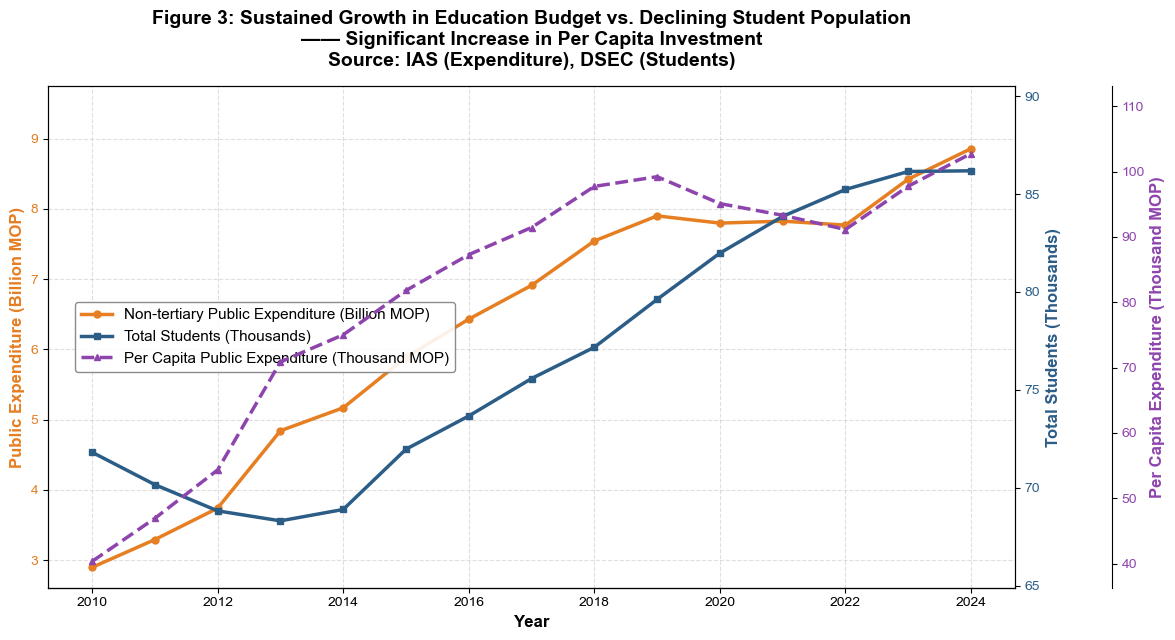

In [44]:

# ==========================================
# 1. Setup Fonts (English Only)
# ==========================================
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['axes.unicode_minus'] = False

# ==========================================
# 2. Load and Process Data
# ==========================================
# --- Load Public Expenditure ---
df_exp = pd.read_csv('csvs/5. Public expenditure_nontertiary_ias.csv', encoding='utf-8-sig')
df_exp.columns = ['Year', 'Expenditure_Million']
# Convert to Billion (Billion MOP)
df_exp['Expenditure_Billion'] = df_exp['Expenditure_Million'] / 1000 

# --- Load Student Enrollments ---
df_edu = pd.read_csv('csvs/6. Students_enrolled_3 education_stages_dsec.csv', encoding='utf-8-sig')
df_edu.columns = [col.replace('\n', ' ').strip() for col in df_edu.columns]
df_edu = df_edu.rename(columns={
    'Unnamed: 0': 'Year_Range',
    'Students enrolled Pre-primary education': 'Pre_primary',
    'Students enrolled Primary education': 'Primary',
    'Students enrolled Secondary (Inclued vocational-technical) education': 'Secondary'
})

# Extract year and calculate Total Students
df_edu['Year'] = df_edu['Year_Range'].apply(lambda x: int(str(x).split('/')[0]))
df_edu['Total_Students'] = df_edu['Pre_primary'] + df_edu['Primary'] + df_edu['Secondary']
# Convert to Thousands
df_edu['Total_Students_Thousands'] = df_edu['Total_Students'] / 1000

# --- Merge Data (Inner join to align available years, 2010-2024) ---
df_merged = pd.merge(df_exp[['Year', 'Expenditure_Billion']], 
                     df_edu[['Year', 'Total_Students_Thousands']], 
                     on='Year', how='inner')

# --- Calculate Per Capita Expenditure ---
# Formula: (Billion * 1000) / Thousands = Thousand MOP per person
df_merged['Per_Capita_Thousand'] = (df_merged['Expenditure_Billion'] * 1000) / df_merged['Total_Students_Thousands']

# Sort by year
df_merged = df_merged.sort_values('Year').reset_index(drop=True)

# ==========================================
# 3. Plotting Setup (Triple Y-Axis)
# ==========================================
fig, ax1 = plt.subplots(figsize=(12, 6.5))
years = df_merged['Year']

# --- Y-axis 1: Left (Public Expenditure) ---
color1 = '#E67E22' # Orange
ax1.set_xlabel('Year', fontsize=12, fontweight='bold')
ax1.set_ylabel('Public Expenditure (Billion MOP)', color=color1, fontsize=12, fontweight='bold')
line1 = ax1.plot(years, df_merged['Expenditure_Billion'], marker='o', markersize=5, 
                 linestyle='-', linewidth=2.5, color=color1, label='Non-tertiary Public Expenditure (Billion MOP)')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_ylim(df_merged['Expenditure_Billion'].min() * 0.9, df_merged['Expenditure_Billion'].max() * 1.1)

# --- Y-axis 2: Right Inner (Total Students) ---
ax2 = ax1.twinx()
color2 = '#2C5D87' # Dark Blue
ax2.set_ylabel('Total Students (Thousands)', color=color2, fontsize=12, fontweight='bold')
line2 = ax2.plot(years, df_merged['Total_Students_Thousands'], marker='s', markersize=5, 
                 linestyle='-', linewidth=2.5, color=color2, label='Total Students (Thousands)')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.set_ylim(df_merged['Total_Students_Thousands'].min() * 0.95, df_merged['Total_Students_Thousands'].max() * 1.05)

# --- Y-axis 3: Right Outer (Per Capita Expenditure) ---
ax3 = ax1.twinx()
# Move the right spine outward
ax3.spines["right"].set_position(("axes", 1.10)) 
ax3.spines["top"].set_visible(False)
ax3.spines["left"].set_visible(False)

color3 = '#8E44AD' # Purple
ax3.set_ylabel('Per Capita Expenditure (Thousand MOP)', color=color3, fontsize=12, fontweight='bold')
line3 = ax3.plot(years, df_merged['Per_Capita_Thousand'], marker='^', markersize=5, 
                 linestyle='--', linewidth=2.5, color=color3, label='Per Capita Public Expenditure (Thousand MOP)')
ax3.tick_params(axis='y', labelcolor=color3)
ax3.set_ylim(df_merged['Per_Capita_Thousand'].min() * 0.9, df_merged['Per_Capita_Thousand'].max() * 1.1)

# ==========================================
# 4. Formatting and Legend (English)
# ==========================================
plt.title('Figure 3: Sustained Growth in Education Budget vs. Declining Student Population\n'
          '—— Significant Increase in Per Capita Investment\n'
          'Source: IAS (Expenditure), DSEC (Students)', 
          fontsize=14, pad=15, fontweight='bold')

# X-ticks (Every 2 years)
ax1.set_xticks(np.arange(years.min(), years.max() + 1, 2))

# Grid
ax1.grid(True, linestyle='--', alpha=0.4)

# Merge Legends
lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center left', bbox_to_anchor=(0.02, 0.5), 
           frameon=True, facecolor='white', framealpha=0.9, edgecolor='gray', fontsize=11)

# Adjust layout
plt.tight_layout()
plt.subplots_adjust(right=0.85)

# Save and Show
plt.savefig('Figures/Figure3_Education_Expenditure_vs_Students.png', dpi=300, bbox_inches='tight')
print("Chart successfully saved as 'Figure3_Education_Expenditure_vs_Students.png'.")
plt.show()

Figure 4

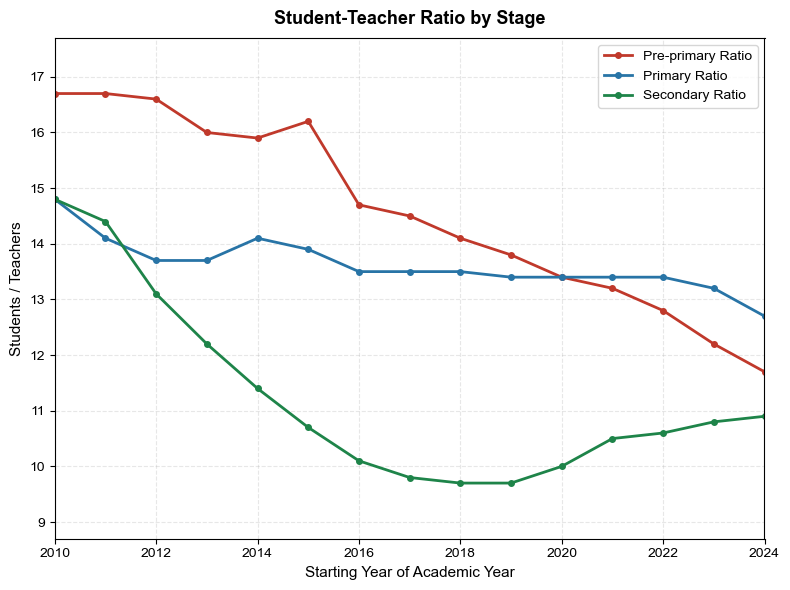

In [58]:
# 1. Setup Fonts (English Only)
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['axes.unicode_minus'] = False

# 2. Load and Process Real Data
df_ratio = pd.read_csv('csvs/8. Pupil-teacher ratio_dsec.csv', encoding='utf-8-sig')
df_ratio.columns = [col.replace('\n', ' ').strip() for col in df_ratio.columns]
df_ratio = df_ratio.rename(columns={
    'Period (Sort)': 'Year_Range',
    'Pupil-teacher ratio Pre-primary education': 'Pre_primary_Ratio',
    'Pupil-teacher ratio Primary education': 'Primary_Ratio',
    'Pupil-teacher ratio Secondary education': 'Secondary_Ratio'
})

# Extract year and filter up to 2024
df_ratio['Year'] = df_ratio['Year_Range'].apply(lambda x: int(str(x).split('/')[0]))
df_ratio = df_ratio[df_ratio['Year'] <= 2024].reset_index(drop=True)

# 3. Plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Define colors and labels
colors = {'Pre_primary_Ratio': '#C0392B', 'Primary_Ratio': '#2874A6', 'Secondary_Ratio': '#1E8449'}
labels = {'Pre_primary_Ratio': 'Pre-primary Ratio', 'Primary_Ratio': 'Primary Ratio', 'Secondary_Ratio': 'Secondary Ratio'}

# Plot the three continuous lines
for col in colors.keys():
    ax.plot(df_ratio['Year'], df_ratio[col], marker='o', markersize=4, 
            linestyle='-', linewidth=2, color=colors[col], label=labels[col])

# Formatting
ax.set_title('Student-Teacher Ratio by Stage', fontsize=13, pad=10, fontweight='bold')
ax.set_xlabel('Starting Year of Academic Year', fontsize=11)
ax.set_ylabel('Students / Teachers', fontsize=11)
ax.set_xlim(2010, 2024)
ax.set_xticks(np.arange(2010, 2025, 2))

# Auto-adjust Y-axis limits based on real data
min_val = df_ratio[list(colors.keys())].min().min()
max_val = df_ratio[list(colors.keys())].max().max()
ax.set_ylim(min_val - 1, max_val + 1)

ax.grid(True, linestyle='--', alpha=0.3)
ax.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig('Figures/Figure4_Student-Teacher Ratio by stage.png', dpi=300, bbox_inches='tight')
plt.show()